<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta8g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

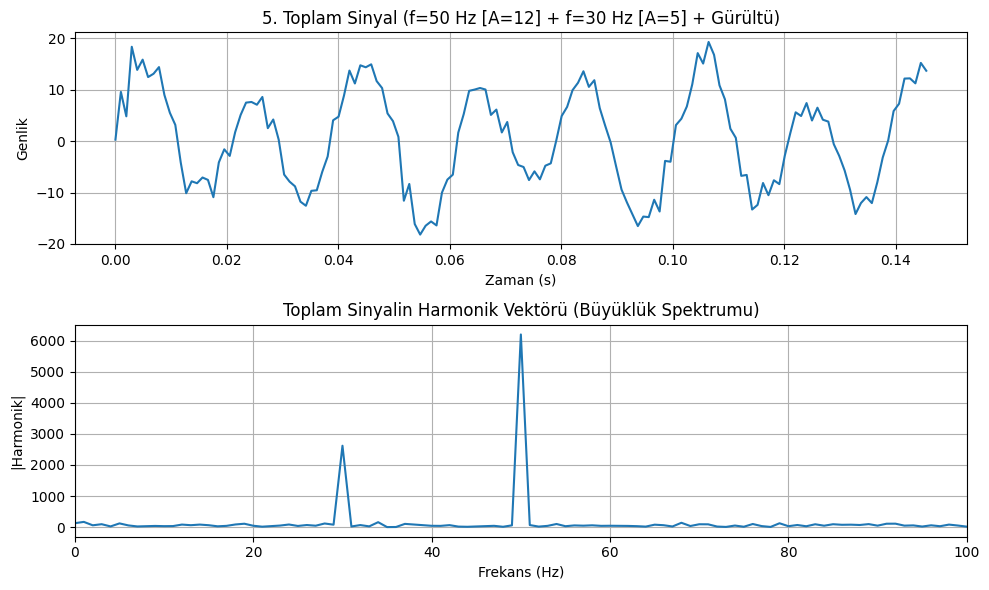

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 1024
fs = 1024.0
t = np.arange(N) / fs
rng = np.random.default_rng(21)

# f=50, A=12 ve f=30, A=5 (gürültülü)
sinyal_50 = 12.0 * np.sin(2 * np.pi * 50.0 * t) + rng.normal(0, 1.5, size=N)
sinyal_30 = 5.0 * np.sin(2 * np.pi * 30.0 * t) + rng.normal(0, 1.5, size=N)

# Ayrı ayrı DFT
dft_50 = np.fft.fft(sinyal_50)
dft_30 = np.fft.fft(sinyal_30)

# Toplam sinyal ve DFT'si
toplam_sinyal = sinyal_50 + sinyal_30
dft_toplam = np.fft.fft(toplam_sinyal)
frekanslar = np.fft.fftfreq(N, d=1.0 / fs)
pozitif_maske = frekanslar >= 0

plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(t[:150], toplam_sinyal[:150])
plt.title("5. Toplam Sinyal (f=50 Hz [A=12] + f=30 Hz [A=5] + Gürültü)")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(frekanslar[pozitif_maske], np.abs(dft_toplam[pozitif_maske]))
plt.xlim(0, 100)
plt.title("Toplam Sinyalin Harmonik Vektörü (Büyüklük Spektrumu)")
plt.xlabel("Frekans (Hz)")
plt.ylabel("|Harmonik|")
plt.grid(True)

plt.tight_layout()
plt.show()